# Ensemble Learning on Sri Lankan Weather

**Author:** Gurusinghe W.A.L.M (224066J) · BSc (Hons) IT, University of Moratuwa
**Date:** November 2026
**Live dashboard:** https://sl-weather-ensembles.streamlit.app

Two monsoons run Sri Lanka's year. The south-west monsoon (May–September) soaks the
west coast and the hill country, and the north-east monsoon (December–February) brings
the rain to the north and east. Farmers plan the Yala and Maha seasons around them,
floods follow them, and dengue cases climb a few weeks after the heavy rains. So a
simple question is worth asking city by city: *will it rain tomorrow, how much, and how
hot will it get?* In this notebook I try to answer that with bagging, boosting,
stacking and two hybrid models, and I look at *why* each one does well or badly.

## 1. Data loading and overview

The data is the Kaggle *Sri Lanka Weather Dataset* by `rasulmah`: daily Open-Meteo
values for 30 cities. I checked the downloaded file against its expected MD5
(`99509b8a…`) before starting.

In [1]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import features as fe, models as md

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)

RAW = ROOT / "data/raw/SriLanka_Weather_Dataset.csv"
if not RAW.exists():  # fallback mirror of the same file, used only if the CSV is missing
    import urllib.request
    RAW.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/dilshanpga/dengue-forecast/main/data/raw/"
        "SriLanka_Weather_Dataset.csv", RAW)

ART, FIG, MOD = ROOT / "artifacts", ROOT / "artifacts/figures", ROOT / "artifacts/models"
for p in (FIG, MOD):
    p.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
FAMILY_COL = {"Baseline": "#9aa0a6", "Bagging": "#2a9d8f", "Boosting": "#e76f51",
              "Stacking": "#264653", "Hybrid": "#e9c46a"}
SEASON_COL = {"SW": "#2a9d8f", "NE": "#e76f51", "Inter": "#b0b5ba"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

raw = pd.read_csv(RAW)
print("shape:", raw.shape)
raw.head()

shape: (147480, 24)


,time,weathercode,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,apparent_temperature_mean,sunrise,sunset,shortwave_radiation_sum,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,windspeed_10m_max,windgusts_10m_max,winddirection_10m_dominant,et0_fao_evapotranspiration,latitude,longitude,elevation,country,city
0,2010-01-01,2,30.0,22.7,26.1,34.4,25.2,29.2,2010-01-01T00:52,2010-01-01T12:35,20.92,0.0,0.0,0.0,0.0,11.7,27.4,20,4.58,7.0,79.899994,16.0,Sri Lanka,Colombo
1,2010-01-02,51,29.9,23.5,26.2,33.8,26.2,29.8,2010-01-02T00:52,2010-01-02T12:36,17.71,0.1,0.1,0.0,1.0,13.0,27.0,24,3.84,7.0,79.899994,16.0,Sri Lanka,Colombo
2,2010-01-03,51,29.5,23.2,26.0,34.3,26.3,29.9,2010-01-03T00:53,2010-01-03T12:36,17.76,0.6,0.6,0.0,3.0,12.3,27.4,16,3.65,7.0,79.899994,16.0,Sri Lanka,Colombo
3,2010-01-04,2,28.9,21.9,25.3,31.6,23.4,27.8,2010-01-04T00:53,2010-01-04T12:37,16.50,0.0,0.0,0.0,0.0,17.0,34.6,356,3.79,7.0,79.899994,16.0,Sri Lanka,Colombo
4,2010-01-05,1,28.1,21.3,24.5,30.1,23.1,26.1,2010-01-05T00:53,2010-01-05T12:37,23.61,0.0,0.0,0.0,0.0,18.7,37.1,355,4.97,7.0,79.899994,16.0,Sri Lanka,Colombo


In [2]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
raw.dtypes.to_frame("dtype").T

,time,weathercode,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,apparent_temperature_mean,sunrise,sunset,shortwave_radiation_sum,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,windspeed_10m_max,windgusts_10m_max,winddirection_10m_dominant,et0_fao_evapotranspiration,latitude,longitude,elevation,country,city
dtype,str,int64,float64,float64,float64,float64,float64,float64,str,str,float64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,str,str


In [3]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
print(f"{raw.city.nunique()} cities, from {raw.time.min()} to {raw.time.max()}")
print(", ".join(sorted(raw.city.unique())))

30 cities, from 2010-01-01 to 2023-06-17
Athurugiriya, Badulla, Bentota, Colombo, Galle, Gampaha, Hambantota, Hatton, Jaffna, Kalmunai, Kalutara, Kandy, Kesbewa, Kolonnawa, Kurunegala, Mabole, Maharagama, Mannar, Matale, Matara, Moratuwa, Mount Lavinia, Negombo, Oruwala, Pothuhera, Puttalam, Ratnapura, Sri Jayewardenepura Kotte, Trincomalee, Weligama


In [4]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
quality = pd.DataFrame({"missing": raw.isna().sum(),
                        "missing_%": (raw.isna().mean() * 100).round(2)})
dups = pd.Series({"duplicate rows": raw.duplicated().sum(),
                  "duplicate (city, date) pairs": raw.duplicated(["city", "time"]).sum()},
                 name="count")
display(quality)
display(dups.to_frame())

,missing,missing_%
time,0,0.0
weathercode,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
temperature_2m_mean,0,0.0
apparent_temperature_max,0,0.0
apparent_temperature_min,0,0.0
apparent_temperature_mean,0,0.0
sunrise,0,0.0
sunset,0,0.0


,count
duplicate rows,0
"duplicate (city, date) pairs",0


## 2. Exploratory data analysis

Six plots, each one picked because it shapes a modelling decision later on.

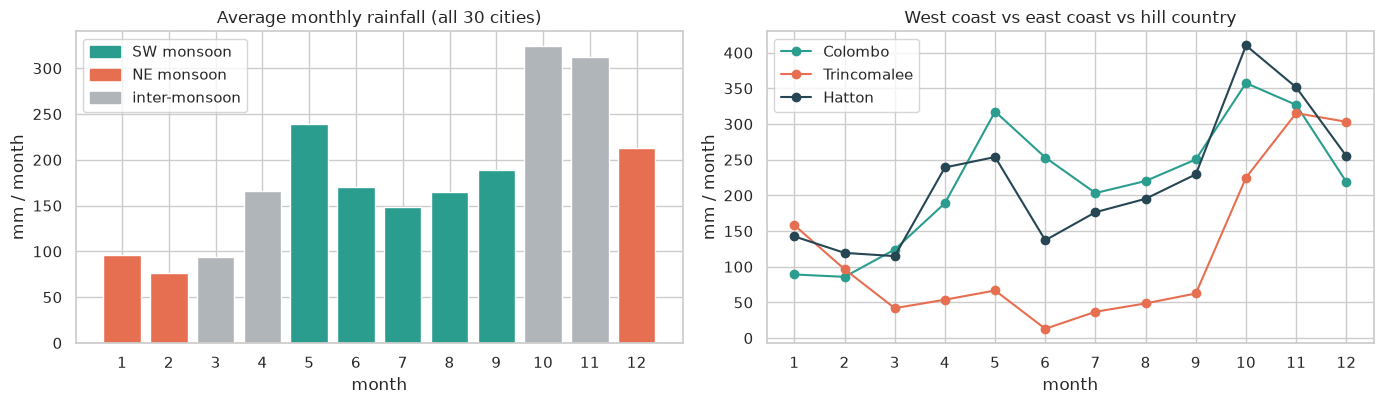

In [5]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
daily = fe.clean(fe.load_raw(RAW))
monthly = (daily.assign(ym=daily.time.dt.to_period("M"))
                .groupby(["city", "ym"]).precipitation_sum.sum().reset_index())
monthly["month"] = monthly.ym.dt.month
avg = monthly.groupby("month").precipitation_sum.mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(avg.index, avg.values,
          color=[SEASON_COL[s] for s in fe.monsoon_season(pd.Series(avg.index))])
ax[0].set(title="Average monthly rainfall (all 30 cities)", xlabel="month", ylabel="mm / month",
          xticks=range(1, 13))
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=SEASON_COL[k], label=v) for k, v in
                      [("SW", "SW monsoon"), ("NE", "NE monsoon"), ("Inter", "inter-monsoon")]])
for c, col in [("Colombo", "#2a9d8f"), ("Trincomalee", "#e76f51"), ("Hatton", "#264653")]:
    s = monthly[monthly.city == c].groupby("month").precipitation_sum.mean()
    ax[1].plot(s.index, s.values, marker="o", label=c, color=col)
ax[1].set(title="West coast vs east coast vs hill country", xlabel="month",
          ylabel="mm / month", xticks=range(1, 13))
ax[1].legend()
savefig("eda_monthly_rain")

The yearly rhythm is clear. Colombo peaks in May and again in October–November, while
Trincomalee on the east coast is fairly dry in mid-year and gets most of its rain from
October to January. Across the island, the wettest months are actually October and
November, the inter-monsoon, when storms hit both coasts. The month and the monsoon flag are going to matter, and they act
differently depending on *where* the city is.

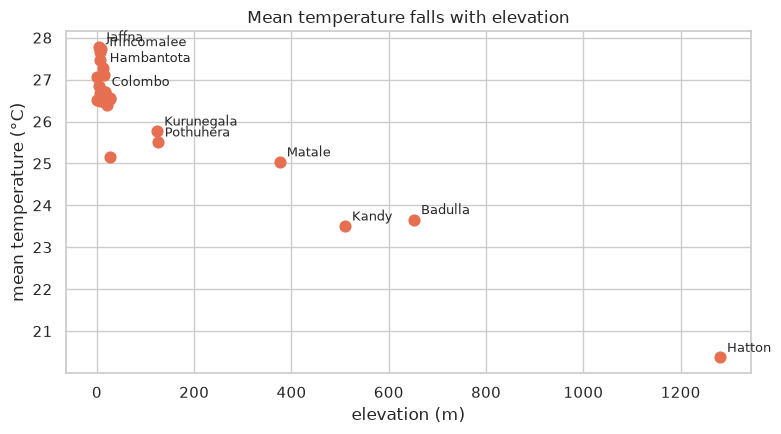

In [6]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
city_stats = daily.groupby("city").agg(
    tmean=("temperature_2m_mean", "mean"), rain=("precipitation_sum", "mean"),
    elevation=("elevation", "first"), lat=("latitude", "first"), lon=("longitude", "first"))
city_stats["annual_rain_mm"] = city_stats.rain * 365.25

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(city_stats.elevation, city_stats.tmean, s=60, c="#e76f51")
for name, r in city_stats.iterrows():
    if r.elevation > 100 or name in ("Jaffna", "Trincomalee", "Colombo", "Hambantota"):
        ax.annotate(name, (r.elevation, r.tmean), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set(title="Mean temperature falls with elevation", xlabel="elevation (m)", ylabel="mean temperature (°C)")
savefig("eda_temp_elevation")

Hatton, at about 1,280 m, is roughly 7 °C cooler than the coast, so elevation alone
separates the hill country from everywhere else. That's why latitude, longitude and
elevation go into the features.

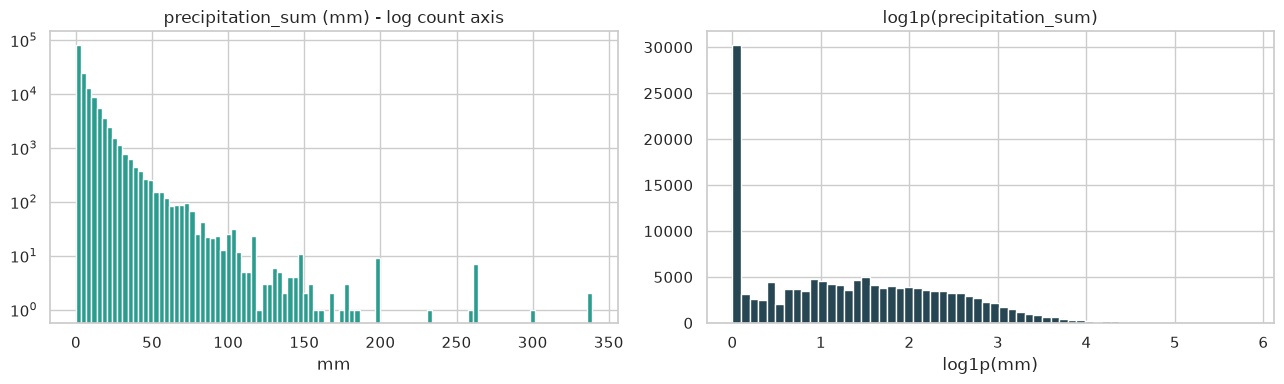

skewness 6.0 | dry days (0 mm) 18.1% | days >= 1 mm 67.0% | 99th percentile 47 mm | max 339 mm


In [7]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
p = daily.precipitation_sum
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(p, bins=100, color="#2a9d8f"); ax[0].set_yscale("log")
ax[0].set(title="precipitation_sum (mm) - log count axis", xlabel="mm")
ax[1].hist(np.log1p(p), bins=60, color="#264653")
ax[1].set(title="log1p(precipitation_sum)", xlabel="log1p(mm)")
savefig("eda_rain_distribution")
print(f"skewness {p.skew():.1f} | dry days (0 mm) {np.mean(p == 0):.1%} | days >= 1 mm {np.mean(p >= 1):.1%} "
      f"| 99th percentile {p.quantile(.99):.0f} mm | max {p.max():.0f} mm")

Rainfall has a long right tail: most days are light, and a few storms drop over
100 mm. A squared-error model trained on raw millimetres would chase those few storms,
so I predict `log1p(mm)` and also run a separate "will it rain ≥ 1 mm?" classifier.

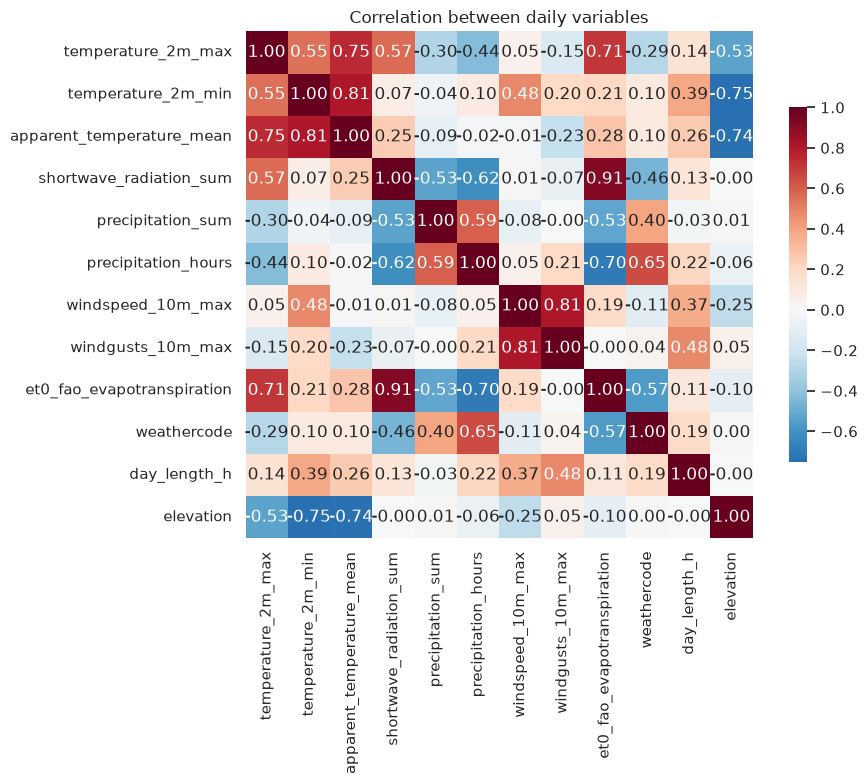

In [8]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
num_cols = ["temperature_2m_max", "temperature_2m_min", "apparent_temperature_mean",
            "shortwave_radiation_sum", "precipitation_sum", "precipitation_hours",
            "windspeed_10m_max", "windgusts_10m_max", "et0_fao_evapotranspiration",
            "weathercode", "day_length_h", "elevation"]
plt.figure(figsize=(10, 8))
sns.heatmap(daily[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True,
            cbar_kws={"shrink": .7})
plt.title("Correlation between daily variables")
savefig("eda_correlation")

Rain goes together with precipitation hours and the weather code, and against
radiation and ET0 (cloudy days are wet days). Temperature and apparent temperature
are almost the same signal. Trees don't mind redundant features, but this is a
reminder that the plain linear baseline will have some collinearity.

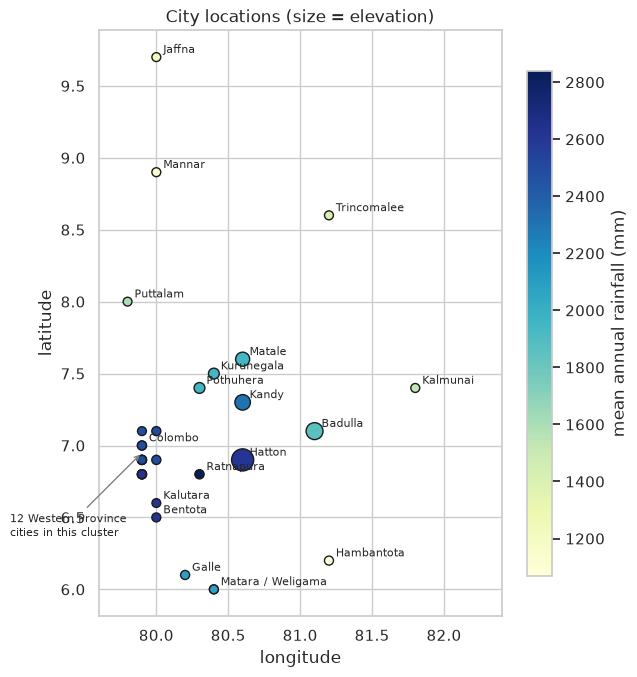

In [9]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
fig, ax = plt.subplots(figsize=(6.5, 8))
sc = ax.scatter(city_stats.lon, city_stats.lat, c=city_stats.annual_rain_mm, cmap="YlGnBu",
                s=40 + city_stats.elevation / 6, edgecolor="k")
plt.colorbar(sc, label="mean annual rainfall (mm)", shrink=.7)
western = (city_stats.lat.between(6.7, 7.2)) & (city_stats.lon < 80.05)
labels = (city_stats[~western | (city_stats.index == "Colombo")].reset_index()
          .groupby(["lon", "lat"]).city.agg(" / ".join))
for (lon, lat), name in labels.items():
    ax.annotate(name, (lon, lat), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_xlim(79.6, 82.4)
ax.annotate(f"{western.sum()} Western Province\ncities in this cluster", (79.9, 6.95),
            xytext=(-95, -60), textcoords="offset points", fontsize=8,
            arrowprops=dict(arrowstyle="->", color="grey"))
ax.set(title="City locations (size = elevation)", xlabel="longitude", ylabel="latitude")
ax.set_aspect("equal")
savefig("eda_city_map")

,city_a,city_b,mean |Δ temp|,rain corr
404,Mount Lavinia,Sri Jayewardenepura Kotte,0.0000,0.9013
95,Colombo,Mabole,0.0000,0.9013
289,Kesbewa,Moratuwa,0.0485,1.0000
285,Kesbewa,Maharagama,0.0510,1.0000
389,Matara,Weligama,0.0511,1.0000
306,Kolonnawa,Mount Lavinia,0.0514,0.9013
312,Kolonnawa,Sri Jayewardenepura Kotte,0.0514,1.0000
335,Mabole,Mount Lavinia,0.0662,0.9013


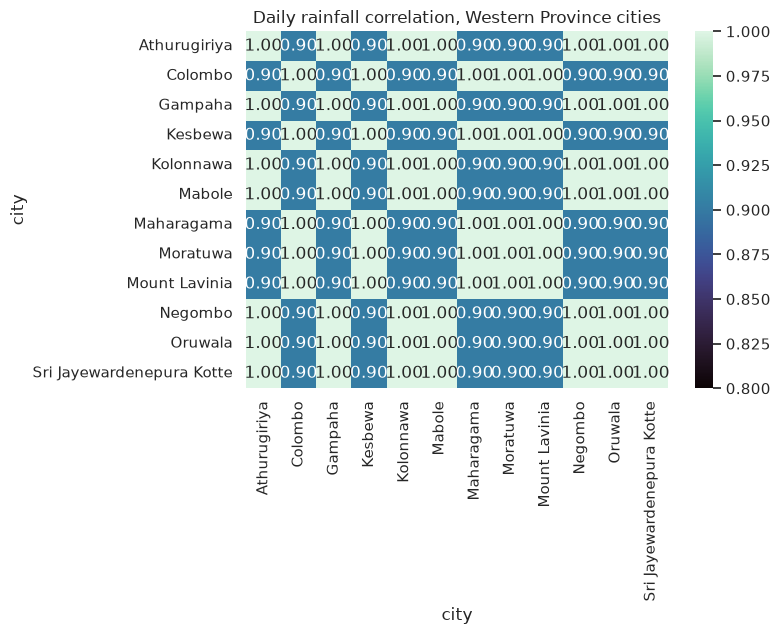

In [10]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
piv = daily.pivot(index="time", columns="city", values="temperature_2m_mean")
pr = daily.pivot(index="time", columns="city", values="precipitation_sum")
rows = []
cols = list(piv.columns)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        rows.append((a, b, (piv[a] - piv[b]).abs().mean(), pr[a].corr(pr[b])))
pairs = pd.DataFrame(rows, columns=["city_a", "city_b", "mean |Δ temp|", "rain corr"])
display(pairs.sort_values("mean |Δ temp|").head(8).round(4))

wp = city_stats[western].index.tolist()
plt.figure(figsize=(8, 6.5))
sns.heatmap(pr[wp].corr(), annot=True, fmt=".2f", cmap="mako", vmin=.8, vmax=1)
plt.title("Daily rainfall correlation, Western Province cities")
savefig("eda_shared_grid")

**Nearby cities share grid cells.** Open-Meteo values are interpolated from a
reanalysis grid, so cities only a few kilometres apart can land on the same cell, and
temperature and rain come from different grids. Colombo and Mabole have exactly the
same temperatures every day (so do Mount Lavinia and Sri Jayewardenepura Kotte), while
Colombo and Mount Lavinia have exactly the same rainfall. The rest of the Western
cluster is highly correlated too. This matters for evaluation: if I shuffle rows
randomly, Colombo's 3 March can end up in the test set while its twin's 3 March sits
in training (see the demo in Section 3).

## 3. Cleaning and feature engineering

All of the logic lives in `src/features.py`, so the notebook and the dashboard share
exactly the same code. First, the columns I drop:

In [11]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
print("rain_sum identical to precipitation_sum ->", raw.rain_sum.equals(raw.precipitation_sum))
print("snowfall_sum unique values             ->", raw.snowfall_sum.unique())
print("country unique values                  ->", raw.country.unique())
print("dropped:", fe.DROP_COLS, "(sunrise/sunset are first turned into day_length_h)")

rain_sum identical to precipitation_sum -> True
snowfall_sum unique values             -> [0.]
country unique values                  -> <ArrowStringArray>
['Sri Lanka']
Length: 1, dtype: str
dropped: ['rain_sum', 'snowfall_sum', 'country', 'sunrise', 'sunset'] (sunrise/sunset are first turned into day_length_h)


**What gets built** (all inside `groupby('city')`, so one city's history never leaks
into another's):

* **calendar:** year, month, day-of-year as sin/cos, and SW / NE monsoon flags
* **wind direction** as sin/cos, so 359° and 1° end up close together
* **day-t values** of every weather variable, plus lags 1, 2, 3 and 7 and 7- and
  30-day rolling means of the main ones
* **location:** latitude, longitude, elevation and a city code (CatBoost gets the city
  name as a native categorical)

**Targets (day t+1):**

* `y_rain_next`: log1p of tomorrow's rainfall (regression)
* `y_rain_flag`: tomorrow ≥ 1 mm (binary)
* `y_tmax_next`: tomorrow's maximum temperature (regression)

**Leakage rules I stick to:**

* Variables such as `precipitation_hours`, `weathercode`, apparent temperature and
  ET0 are basically descriptions of the day's rain and heat. If I used *tomorrow's*
  value of any of them, the model would be reading the answer. So they only appear as
  day-t or lagged values.
* Rolling windows end on day t.
* The first 30 days of each city (where the lags and rolling means are still
  undefined) are dropped, along with the last day, which has no "tomorrow".
* The split is by date, never random.

In [12]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
data = fe.build_dataset(RAW)
FEATURES = fe.feature_columns()
TARGET_COLS = list(fe.TARGETS.values())
print("modelling table:", data.shape, "| features:", len(FEATURES))

# leakage guards
assert not set(FEATURES) & set(TARGET_COLS + ["rain_next_mm"]), "a target slipped into the features"
col = data[data.city == "Kandy"].set_index("time")
assert np.allclose(col.y_tmax_next.iloc[:-1].values, col.temperature_2m_max.iloc[1:].values), "target is not t+1"
print("checks passed: no target column in X, and every target is the next day's value")

groups = {"day-t": fe.DAY_T_COLS, "lags": [f for f in FEATURES if "_lag" in f],
          "rolling": [f for f in FEATURES if "_roll" in f], "calendar": fe.CALENDAR_COLS,
          "location": fe.STATIC_COLS}
pd.Series({k: len(v) for k, v in groups.items()}, name="n features").to_frame().T

modelling table: (146580, 75) | features: 68
checks passed: no target column in X, and every target is the next day's value


,day-t,lags,rolling,calendar,location
n features,16,32,10,6,4


In [13]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
tr, va, te = fe.time_split(data)
split_tbl = pd.DataFrame({
    name: {"rows": int(m.sum()), "from": data.time[m].min().date(), "to": data.time[m].max().date(),
           "rain-day share": round(data.y_rain_flag[m].mean(), 3)}
    for name, m in [("train", tr), ("validation", va), ("test", te)]}).T
assert data.time[tr].max() < data.time[va].min() and data.time[va].max() < data.time[te].min()
split_tbl

,rows,from,to,rain-day share
train,119670,2010-01-30,2020-12-31,0.667
validation,10950,2021-01-01,2021-12-31,0.713
test,15960,2022-01-01,2023-06-16,0.686


In [14]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
X, CITY = data[FEATURES], data.city
Y = {task: data[col] for task, col in fe.TARGETS.items()}
Y["rain_flag"] = Y["rain_flag"].astype(int)
XCB = md.catboost_frame(X, CITY)   # same features, but 'city' as a text categorical
TASKS = list(fe.TARGETS)
print({t: Y[t].describe()[["mean", "std"]].round(3).to_dict() for t in TASKS})

{'rain_amount': {'mean': 1.342, 'std': 1.063}, 'rain_flag': {'mean': 0.672, 'std': 0.469}, 'tmax': {'mean': 29.245, 'std': 2.121}}


### Leakage demo: random split vs time split

The same random forest, the same number of training rows. The only change is *how*
I pick the test rows.

In [15]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
from sklearn.model_selection import train_test_split

demo = []
rand_tr, rand_te = train_test_split(np.arange(len(data)), train_size=int(tr.sum()), random_state=42)
for task in ["tmax", "rain_amount"]:
    for split, (a, b) in {"random split": (rand_tr, rand_te),
                          "time split": (np.where(tr)[0], np.where(te)[0])}.items():
        m = md.make_rf(task, n_estimators=100, min_samples_leaf=2).fit(X.iloc[a], Y[task].iloc[a])
        demo.append({"task": task, "split": split, **md.regression_metrics(Y[task].iloc[b], m.predict(X.iloc[b]))})
        del m
demo = pd.DataFrame(demo).set_index(["task", "split"]).round(3)
demo

MAE   RMSE     R2
task        split                            
tmax        random split  0.425  0.609  0.918
            time split    0.607  0.810  0.848
rain_amount random split  0.318  0.493  0.787
            time split    0.570  0.740  0.465

The random split looks better on both tasks. That's not because the model is better;
the test set just isn't independent of training. With random rows, a test day almost
always has its "twin" from a neighbouring (or identical) grid cell **on the same date**
in the training set, so the model partly looks up the answer. A random split also
spreads every year across both sets, so it never has to face a genuinely new year.
The time split is the honest one, and it's the only one I use from here on.

## 4. Baselines

Any ensemble has to beat these to be worth its training time:

* **Persistence:** tomorrow equals today.
* **Climatology:** the training-period average for that city and calendar month.
* **Linear:** Ridge for regression and LogisticRegression for the rain flag, with the
  city one-hot encoded and the other features standardised.

In [16]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
results = {t: {} for t in TASKS}      # test-set metrics
preds = {t: {} for t in TASKS}        # test-set predictions (probabilities for rain_flag)
val_preds = {t: {} for t in TASKS}

def record(task, name, p_test, seconds, p_val=None, family=None):
    m = md.score(task, Y[task][te], p_test)
    results[task][name] = {"family": family or md.FAMILY[name], **m, "train_time_s": round(seconds, 2)}
    preds[task][name] = np.asarray(p_test, dtype=float)
    if p_val is not None:
        val_preds[task][name] = np.asarray(p_val, dtype=float)
    return m

MAIN = {"tmax": "MAE", "rain_amount": "MAE", "rain_flag": "ROC_AUC"}
def table(task):
    df = pd.DataFrame(results[task]).T
    asc = MAIN[task] != "ROC_AUC"
    num = df.columns.drop("family")
    df[num] = df[num].astype(float).round(4)
    return df.sort_values(MAIN[task], ascending=asc)

# persistence
today = {"tmax": data.temperature_2m_max, "rain_amount": np.log1p(data.precipitation_sum),
         "rain_flag": (data.precipitation_sum >= 1).astype(float)}
for t in TASKS:
    record(t, "Persistence", today[t][te], 0.0)

# climatology: city x month-of-target average from the training years only
tgt_month = (data.time + pd.Timedelta(days=1)).dt.month
for t in TASKS:
    t0 = time.perf_counter()
    clim = Y[t][tr].groupby([CITY[tr], tgt_month[tr]]).mean()
    p = clim.reindex(pd.MultiIndex.from_arrays([CITY[te], tgt_month[te]])).values
    record(t, "Climatology", p, time.perf_counter() - t0)

# linear
for t in TASKS:
    m, s = md.timed_fit(md.make_linear(t, FEATURES), X[tr], Y[t][tr])
    record(t, "Linear", md.predict(m, X[te], t), s, md.predict(m, X[va], t))

for t in TASKS:
    display(table(t).rename_axis(t))

,family,MAE,RMSE,R2,train_time_s
rain_amount,,,,,
Linear,Baseline,0.5813,0.7521,0.4467,0.22
Persistence,Baseline,0.6043,0.8436,0.3038,0.00
Climatology,Baseline,0.7014,0.8908,0.2237,0.01


,family,Accuracy,F1,ROC_AUC,PR_AUC,train_time_s
rain_flag,,,,,,
Linear,Baseline,0.8186,0.8714,0.8825,0.9429,4.27
Climatology,Baseline,0.7493,0.8096,0.8063,0.8963,0.01
Persistence,Baseline,0.8043,0.8574,0.7727,0.8328,0.00


,family,MAE,RMSE,R2,train_time_s
tmax,,,,,
Linear,Baseline,0.6054,0.8226,0.8433,0.22
Persistence,Baseline,0.6916,0.9656,0.7841,0.00
Climatology,Baseline,0.8822,1.1782,0.6785,0.01


## 5. Bagging

Bagging trains many deep trees on bootstrap samples and averages them. Each tree on
its own is noisy, but their mistakes partly cancel. I compare three versions:

* **BaggedTrees:** plain bagging of decision trees, where every split can use every feature
* **RandomForest:** bagging plus a random subset of features at each split, which
  makes the trees less alike
* **ExtraTrees:** also picks the split thresholds at random, which decorrelates the
  trees even more

The random forest is tuned lightly: a 6-candidate randomized search with
`TimeSeriesSplit(3)` on a 30,000-row sample of the training years, kept in time order.

In [17]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

space = {"max_features": [0.2, 0.4, 0.6, "sqrt"], "min_samples_leaf": [2, 5, 10, 20],
         "max_depth": [None, 25]}
rng = np.random.default_rng(42)
sub = np.sort(rng.choice(np.where(tr)[0], 30_000, replace=False))   # data is in date order
best_params, tuning = {}, []
for t in TASKS:
    search = RandomizedSearchCV(
        md.make_rf(t, n_estimators=100), space, n_iter=6, cv=TimeSeriesSplit(3),
        scoring="roc_auc" if md.is_clf(t) else "neg_mean_absolute_error",
        random_state=42, n_jobs=1)
    t0 = time.perf_counter()
    search.fit(X.iloc[sub], Y[t].iloc[sub])
    best_params[t] = search.best_params_
    tuning.append({"task": t, **search.best_params_, "cv score": round(search.best_score_, 4),
                   "search time (s)": round(time.perf_counter() - t0, 1)})
pd.DataFrame(tuning).set_index("task")

,min_samples_leaf,max_features,max_depth,cv score,search time (s)
task,,,,,
rain_amount,5,0.2,25.0,-0.5846,16.6
rain_flag,20,sqrt,NaN,0.8932,17.3
tmax,5,0.6,NaN,-0.5884,18.2


In [18]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
rf_models = {}
for t in TASKS:
    m, s = md.timed_fit(md.make_rf(t, **best_params[t]), X[tr], Y[t][tr])
    record(t, "RandomForest", md.predict(m, X[te], t), s, md.predict(m, X[va], t))
    rf_models[t] = m

    m, s = md.timed_fit(md.make_bagged_trees(t), X[tr], Y[t][tr])
    record(t, "BaggedTrees", md.predict(m, X[te], t), s)
    del m

    m, s = md.timed_fit(md.make_extratrees(t), X[tr], Y[t][tr])
    record(t, "ExtraTrees", md.predict(m, X[te], t), s)
    del m

for t in TASKS:
    display(table(t).query("family in ['Bagging', 'Baseline']").rename_axis(t))

,family,MAE,RMSE,R2,train_time_s
rain_amount,,,,,
ExtraTrees,Bagging,0.5678,0.7395,0.4650,13.13
RandomForest,Bagging,0.5680,0.7367,0.4691,8.20
BaggedTrees,Bagging,0.5748,0.7494,0.4506,18.68
Linear,Baseline,0.5813,0.7521,0.4467,0.22
Persistence,Baseline,0.6043,0.8436,0.3038,0.00
Climatology,Baseline,0.7014,0.8908,0.2237,0.01


,family,Accuracy,F1,ROC_AUC,PR_AUC,train_time_s
rain_flag,,,,,,
Linear,Baseline,0.8186,0.8714,0.8825,0.9429,4.27
RandomForest,Bagging,0.8131,0.8680,0.8821,0.9435,5.08
ExtraTrees,Bagging,0.8145,0.8688,0.8802,0.9421,11.72
BaggedTrees,Bagging,0.8123,0.8665,0.8694,0.9307,14.51
Climatology,Baseline,0.7493,0.8096,0.8063,0.8963,0.01
Persistence,Baseline,0.8043,0.8574,0.7727,0.8328,0.00


,family,MAE,RMSE,R2,train_time_s
tmax,,,,,
ExtraTrees,Bagging,0.6001,0.8050,0.8499,15.22
RandomForest,Bagging,0.6053,0.8108,0.8478,24.37
Linear,Baseline,0.6054,0.8226,0.8433,0.22
BaggedTrees,Bagging,0.6157,0.8251,0.8424,13.11
Persistence,Baseline,0.6916,0.9656,0.7841,0.00
Climatology,Baseline,0.8822,1.1782,0.6785,0.01


In [19]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
# variance in action: one deep tree vs. the average of many
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
rows = []
for t in TASKS:
    tree = (DecisionTreeClassifier if md.is_clf(t) else DecisionTreeRegressor)(min_samples_leaf=5, random_state=42)
    tree.fit(X[tr], Y[t][tr])
    single = md.score(t, Y[t][te], md.predict(tree, X[te], t))[MAIN[t]]
    rows.append({"task": t, "metric": MAIN[t], "single tree": round(single, 4),
                 "BaggedTrees": round(results[t]["BaggedTrees"][MAIN[t]], 4),
                 "RandomForest": round(results[t]["RandomForest"][MAIN[t]], 4)})
pd.DataFrame(rows).set_index("task")

,metric,single tree,BaggedTrees,RandomForest
task,,,,
rain_amount,MAE,0.7822,0.5748,0.5680
rain_flag,ROC_AUC,0.7308,0.8694,0.8821
tmax,MAE,0.8228,0.6157,0.6053


A single deep tree has low bias but huge variance: it memorises noise in the training
years. Averaging 50–200 of them removes most of that noise, which is exactly what
bagging is for. Random feature subsets add a little more on top, because trees that
look at different features make *different* mistakes, and different mistakes average
out better.

## 6. Boosting

Boosting works the other way round from bagging. Each new shallow tree fits the
errors the ensemble is still making, so it chips away at **bias**. Keep adding trees,
though, and it starts fitting noise, so XGBoost, LightGBM and CatBoost all use **early
stopping on the 2021 validation year**: training stops once the validation loss hasn't
improved for 50–100 rounds. HistGradientBoosting uses a fixed 400 rounds with a small
learning rate and shallow trees, so it is a fairly tame "no early stopping" reference.

In [20]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
import lightgbm as lgb

best_iter = {t: {} for t in TASKS}
boost_models = {t: {} for t in TASKS}
for t in TASKS:
    m, s = md.timed_fit(md.make_hgb(t), X[tr], Y[t][tr])
    record(t, "HistGB", md.predict(m, X[te], t), s)
    boost_models[t]["HistGB"] = m

    m, s = md.timed_fit(md.make_xgb(t), X[tr], Y[t][tr], eval_set=[(X[va], Y[t][va])], verbose=False)
    record(t, "XGBoost", md.predict(m, X[te], t), s, md.predict(m, X[va], t))
    best_iter[t]["XGBoost"] = m.best_iteration + 1
    boost_models[t]["XGBoost"] = m

    m, s = md.timed_fit(md.make_lgbm(t), X[tr], Y[t][tr], eval_set=[(X[va], Y[t][va])],
                        callbacks=[lgb.early_stopping(100, verbose=False)])
    record(t, "LightGBM", md.predict(m, X[te], t), s, md.predict(m, X[va], t))
    best_iter[t]["LightGBM"] = m.best_iteration_
    boost_models[t]["LightGBM"] = m

    m, s = md.timed_fit(md.make_catboost(t), XCB[tr], Y[t][tr], eval_set=(XCB[va], Y[t][va]),
                        early_stopping_rounds=100)
    record(t, "CatBoost", md.predict(m, XCB[te], t), s, md.predict(m, XCB[va], t))
    best_iter[t]["CatBoost"] = m.get_best_iteration() + 1
    boost_models[t]["CatBoost"] = m

display(pd.DataFrame(best_iter).rename_axis("trees kept by early stopping"))
for t in TASKS:
    display(table(t).query("family in ['Boosting', 'Bagging']").rename_axis(t))

,rain_amount,rain_flag,tmax
trees kept by early stopping,,,
XGBoost,103,186,172
LightGBM,74,193,141
CatBoost,96,285,274


,family,MAE,RMSE,R2,train_time_s
rain_amount,,,,,
CatBoost,Boosting,0.5585,0.7319,0.4761,3.78
XGBoost,Boosting,0.5597,0.7350,0.4715,1.57
HistGB,Boosting,0.5615,0.7398,0.4646,2.64
LightGBM,Boosting,0.5658,0.7370,0.4686,2.25
ExtraTrees,Bagging,0.5678,0.7395,0.4650,13.13
RandomForest,Bagging,0.5680,0.7367,0.4691,8.20
BaggedTrees,Bagging,0.5748,0.7494,0.4506,18.68


,family,Accuracy,F1,ROC_AUC,PR_AUC,train_time_s
rain_flag,,,,,,
RandomForest,Bagging,0.8131,0.8680,0.8821,0.9435,5.08
ExtraTrees,Bagging,0.8145,0.8688,0.8802,0.9421,11.72
XGBoost,Boosting,0.8147,0.8668,0.8801,0.9419,2.72
LightGBM,Boosting,0.8127,0.8651,0.8797,0.9425,8.08
CatBoost,Boosting,0.8157,0.8676,0.8788,0.9418,9.83
HistGB,Boosting,0.8138,0.8652,0.8785,0.9415,3.17
BaggedTrees,Bagging,0.8123,0.8665,0.8694,0.9307,14.51


,family,MAE,RMSE,R2,train_time_s
tmax,,,,,
HistGB,Boosting,0.5943,0.8000,0.8518,2.77
XGBoost,Boosting,0.5946,0.8006,0.8516,5.57
LightGBM,Boosting,0.5950,0.8012,0.8513,10.52
CatBoost,Boosting,0.5956,0.8007,0.8515,6.80
ExtraTrees,Bagging,0.6001,0.8050,0.8499,15.22
RandomForest,Bagging,0.6053,0.8108,0.8478,24.37
BaggedTrees,Bagging,0.6157,0.8251,0.8424,13.11


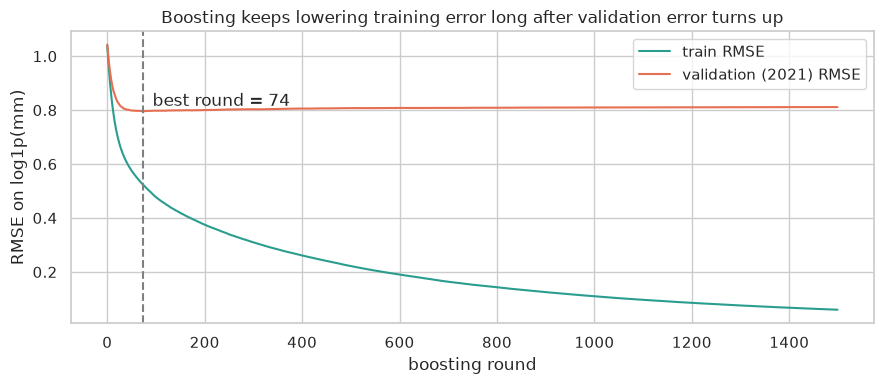

validation RMSE at best round 0.7957 vs after 1500 rounds 0.8113


In [21]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
# what happens without early stopping: a deliberately flexible LightGBM on rain amount
over = md.make_lgbm("rain_amount", n_estimators=1500)
over.set_params(num_leaves=255, min_child_samples=5, learning_rate=0.05)
over.fit(X[tr], Y["rain_amount"][tr], eval_set=[(X[tr], Y["rain_amount"][tr]), (X[va], Y["rain_amount"][va])],
         eval_names=["train", "validation"], eval_metric="l2")
curve = {k: np.sqrt(v["l2"]) for k, v in over.evals_result_.items()}
best = int(np.argmin(curve["validation"]))
plt.figure(figsize=(9, 4))
plt.plot(curve["train"], label="train RMSE", color="#2a9d8f")
plt.plot(curve["validation"], label="validation (2021) RMSE", color="#e76f51")
plt.axvline(best, ls="--", c="grey"); plt.text(best + 20, curve["validation"][best] + .02, f"best round = {best + 1}")
plt.ylabel("RMSE on log1p(mm)"); plt.xlabel("boosting round")
plt.title("Boosting keeps lowering training error long after validation error turns up")
plt.legend(); savefig("boosting_overfit_curve")
print(f"validation RMSE at best round {curve['validation'][best]:.4f} vs after 1500 rounds {curve['validation'][-1]:.4f}")
del over

The training curve keeps falling for all 1,500 rounds, while the validation curve
bottoms out early and then creeps back up. After that point the trees are fitting
noise. That's the overfitting side of boosting, and it's why early stopping isn't
optional.

### CatBoost vs LightGBM

Both are gradient-boosted trees, but they differ in three ways that show up here:

1. **City handling.** LightGBM gets `city_code`, an arbitrary integer, so it has to
   split on "code ≤ 12" and leans on latitude, longitude and elevation instead.
   CatBoost gets the city name as a real categorical and encodes it with *ordered
   target statistics*: each row's city value is encoded using only the rows before it,
   so the encoding never sees the row's own target.
2. **Tree shape.** CatBoost grows *symmetric* (oblivious) trees, with the same split
   at every node of a level. That's a strong regulariser, while LightGBM grows deep,
   lopsided leaf-wise trees.
3. **Ordered boosting** in CatBoost cuts the small prediction shift that plain
   boosting gets from reusing the same rows for gradients and for fitting.

In [22]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
cmp = pd.DataFrame({t: {f"{m} {MAIN[t]}": results[t][m][MAIN[t]] for m in ["LightGBM", "CatBoost"]} |
                       {f"{m} time (s)": results[t][m]["train_time_s"] for m in ["LightGBM", "CatBoost"]} |
                       {f"{m} trees": best_iter[t][m] for m in ["LightGBM", "CatBoost"]}
                    for t in TASKS}).round(4)
cmp

,rain_amount,rain_flag,tmax
LightGBM MAE,0.5658,NaN,0.5950
CatBoost MAE,0.5585,NaN,0.5956
LightGBM time (s),2.2500,8.0800,10.5200
CatBoost time (s),3.7800,9.8300,6.8000
LightGBM trees,74.0000,193.0000,141.0000
CatBoost trees,96.0000,285.0000,274.0000
LightGBM ROC_AUC,NaN,0.8797,NaN
CatBoost ROC_AUC,NaN,0.8788,NaN


In practice the two end up very close. CatBoost is a little ahead on rain amount,
where knowing *which* city it is helps (rain depends on local exposure to each
monsoon), and LightGBM is level or slightly ahead on temperature, where latitude,
longitude and elevation already pin each city down. The four boosting models land
within a few hundredths of each other, so the real gap is boosting vs bagging, not
one library vs another.

## 7. Stacking

Stacking trains a small **meta-learner** on the predictions of several base models:

* **Base models:** RandomForest, LightGBM, CatBoost and the linear model
* **Meta-learner:** Ridge for the two regressions, LogisticRegression for the rain flag

The meta-learner must be trained on *out-of-fold* predictions, otherwise it would
learn to trust base models that have simply memorised the training rows. sklearn's
`StackingRegressor` won't accept `TimeSeriesSplit`, because its OOF predictions need
every row predicted exactly once and the first block never is. So I build the OOF
predictions by hand with `KFold(5, shuffle=False)`. The data is in date order, so each
fold is a contiguous block of about two years.

Some folds are predicted by models trained on *later* years. That's acceptable here
because the meta-learner only learns how much to trust each base model, and the final
test set (2022–23) is still never touched. Doing it by hand also lets CatBoost keep
its native city column. The base models reuse the tuned RF settings and the tree
counts that early stopping chose.

In [23]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
def stack_bases(t):
    return {
        "RandomForest": (lambda: md.make_rf(t, n_estimators=100, **best_params[t]), X),
        "LightGBM": (lambda: md.make_lgbm(t, n_estimators=best_iter[t]["LightGBM"]), X),
        "CatBoost": (lambda: md.make_catboost(t, iterations=best_iter[t]["CatBoost"]), XCB),
        "Linear": (lambda: md.make_linear(t, FEATURES), X),
    }

stack_oof, stack_meta = {}, {}
for t in TASKS:
    t0 = time.perf_counter()
    oof, base_val, base_te = {}, {}, {}
    for name, (make, frame) in stack_bases(t).items():
        oof[name] = md.oof_predictions(make, frame[tr], Y[t][tr], t, n_splits=5)
        full = make().fit(frame[tr], Y[t][tr])
        base_val[name], base_te[name] = md.predict(full, frame[va], t), md.predict(full, frame[te], t)
    O, V, T = (pd.DataFrame(d) for d in (oof, base_val, base_te))
    if md.is_clf(t):
        from sklearn.linear_model import LogisticRegression
        meta = LogisticRegression(max_iter=1000).fit(O, Y[t][tr])
        p_val, p_te = meta.predict_proba(V)[:, 1], meta.predict_proba(T)[:, 1]
    else:
        from sklearn.linear_model import Ridge
        meta = Ridge(alpha=1.0).fit(O, Y[t][tr])
        p_val, p_te = meta.predict(V), meta.predict(T)
    record(t, "Stacking", p_te, time.perf_counter() - t0, p_val)
    stack_oof[t], stack_meta[t] = O, meta
    print(f"{t:12s} meta weights:", dict(zip(O.columns, np.round(np.ravel(meta.coef_), 3))))

for t in TASKS:
    display(table(t).rename_axis(t))

rain_amount  meta weights: {'RandomForest': np.float64(0.187), 'LightGBM': np.float64(0.322), 'CatBoost': np.float64(0.31), 'Linear': np.float64(0.218)}


rain_flag    meta weights: {'RandomForest': np.float64(1.978), 'LightGBM': np.float64(1.084), 'CatBoost': np.float64(0.607), 'Linear': np.float64(2.194)}


tmax         meta weights: {'RandomForest': np.float64(0.178), 'LightGBM': np.float64(0.265), 'CatBoost': np.float64(0.343), 'Linear': np.float64(0.224)}


,family,MAE,RMSE,R2,train_time_s
rain_amount,,,,,
Stacking,Stacking,0.5579,0.7322,0.4755,37.10
CatBoost,Boosting,0.5585,0.7319,0.4761,3.78
XGBoost,Boosting,0.5597,0.7350,0.4715,1.57
HistGB,Boosting,0.5615,0.7398,0.4646,2.64
LightGBM,Boosting,0.5658,0.7370,0.4686,2.25
ExtraTrees,Bagging,0.5678,0.7395,0.4650,13.13
RandomForest,Bagging,0.5680,0.7367,0.4691,8.20
BaggedTrees,Bagging,0.5748,0.7494,0.4506,18.68
Linear,Baseline,0.5813,0.7521,0.4467,0.22


,family,Accuracy,F1,ROC_AUC,PR_AUC,train_time_s
rain_flag,,,,,,
Stacking,Stacking,0.8174,0.8703,0.8850,0.9453,98.11
Linear,Baseline,0.8186,0.8714,0.8825,0.9429,4.27
RandomForest,Bagging,0.8131,0.8680,0.8821,0.9435,5.08
ExtraTrees,Bagging,0.8145,0.8688,0.8802,0.9421,11.72
XGBoost,Boosting,0.8147,0.8668,0.8801,0.9419,2.72
LightGBM,Boosting,0.8127,0.8651,0.8797,0.9425,8.08
CatBoost,Boosting,0.8157,0.8676,0.8788,0.9418,9.83
HistGB,Boosting,0.8138,0.8652,0.8785,0.9415,3.17
BaggedTrees,Bagging,0.8123,0.8665,0.8694,0.9307,14.51


,family,MAE,RMSE,R2,train_time_s
tmax,,,,,
Stacking,Stacking,0.5892,0.7957,0.8534,98.73
HistGB,Boosting,0.5943,0.8000,0.8518,2.77
XGBoost,Boosting,0.5946,0.8006,0.8516,5.57
LightGBM,Boosting,0.5950,0.8012,0.8513,10.52
CatBoost,Boosting,0.5956,0.8007,0.8515,6.80
ExtraTrees,Bagging,0.6001,0.8050,0.8499,15.22
RandomForest,Bagging,0.6053,0.8108,0.8478,24.37
Linear,Baseline,0.6054,0.8226,0.8433,0.22
BaggedTrees,Bagging,0.6157,0.8251,0.8424,13.11


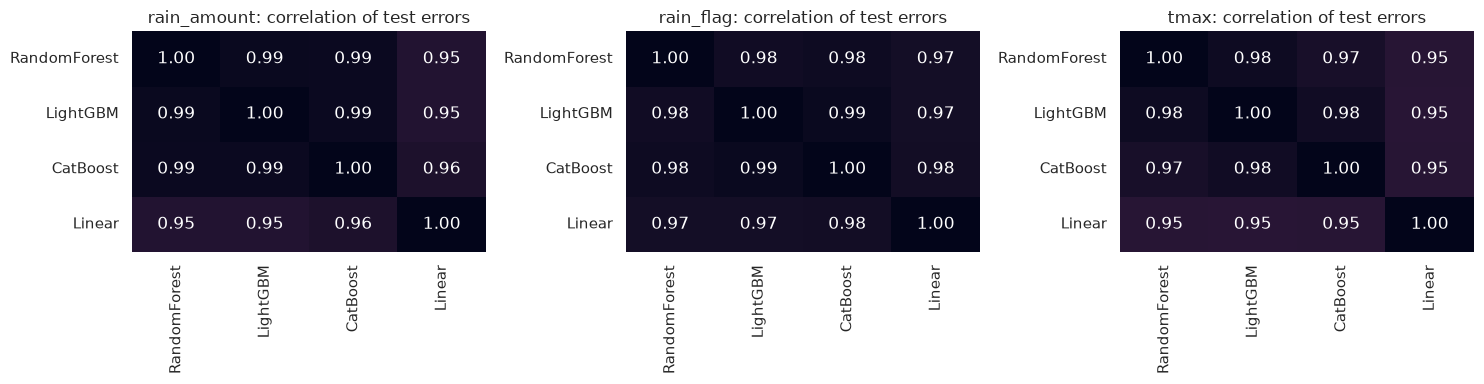

In [24]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
# stacking only helps if the base models make *different* mistakes
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, t in zip(ax, TASKS):
    err = pd.DataFrame({m: Y[t][te].values - preds[t][m] for m in ["RandomForest", "LightGBM", "CatBoost", "Linear"]})
    sns.heatmap(err.corr(), annot=True, fmt=".2f", cmap="rocket_r", vmin=.5, vmax=1, ax=a, cbar=False)
    a.set_title(f"{t}: correlation of test errors")
savefig("stacking_error_correlation")

## 8. Hybrid models

### 8.1 RF + SARIMA (Colombo, weekly mean temperature)

The idea is to split the forecasting work between two models:

* **SARIMA** handles the parts a tree is bad at: the 52-week seasonal cycle and a slow
  drift (the `trend="c"` term with seasonal differencing gives a linear trend).
* A **random forest** then learns whatever SARIMA leaves in its residuals, using
  last week's rain, sunshine and wind.

**Final forecast = SARIMA forecast + RF residual forecast.** SARIMA is fitted on the
training weeks only. Over validation and test, the fitted parameters stay frozen and
only produce one-step-ahead forecasts, so every model predicts next week from data up
to this week.

In [25]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor

col = daily[daily.city == "Colombo"].set_index("time")
wk = col.resample("W").agg({"temperature_2m_mean": "mean", "precipitation_sum": "sum",
                            "shortwave_radiation_sum": "mean", "windspeed_10m_max": "mean"})
y_wk = wk.temperature_2m_mean
w_tr, w_va, w_te = (y_wk.index <= fe.TRAIN_END), (y_wk.index.year == 2021), (y_wk.index >= fe.TEST_START)
print("weeks: train", w_tr.sum(), "| validation", w_va.sum(), "| test", w_te.sum())

ORDER, SORDER = (1, 0, 1), (0, 1, 1, 52)
t0 = time.perf_counter()
sar = SARIMAX(y_wk[w_tr], order=ORDER, seasonal_order=SORDER, trend="c").fit(disp=False, maxiter=200)
sar_time = time.perf_counter() - t0
sar_all = SARIMAX(y_wk, order=ORDER, seasonal_order=SORDER, trend="c").filter(sar.params)
sarima_pred = sar_all.get_prediction(dynamic=False).predicted_mean
print(f"SARIMA fitted in {sar_time:.1f}s, AIC {sar.aic:.1f}")
sar.summary().tables[1]

weeks: train 574 | validation 52 | test 77


SARIMA fitted in 33.2s, AIC 744.5


,coef,std err,z,P>|z|,[0.025,0.975]
intercept,0.0092,0.004,2.335,0.020,0.001,0.017
ar.L1,0.8595,0.029,29.501,0.000,0.802,0.917
ma.L1,-0.4175,0.054,-7.767,0.000,-0.523,-0.312
ma.S.L52,-0.9945,1.614,-0.616,0.538,-4.158,2.169
sigma2,0.1890,0.302,0.627,0.531,-0.402,0.780


In [26]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
# weekly features known at the end of week w-1
F = pd.DataFrame(index=wk.index)
for c in wk.columns:
    for k in (1, 2):
        F[f"{c}_lag{k}"] = wk[c].shift(k)
F["temp_lag52"] = y_wk.shift(52)
woy = wk.index.isocalendar().week.astype(float).values
F["woy_sin"], F["woy_cos"] = np.sin(2 * np.pi * woy / 52.18), np.cos(2 * np.pi * woy / 52.18)
ok = F.notna().all(axis=1) & (np.arange(len(F)) >= 60)          # skip SARIMA's warm-up year
fit_rows, test_rows, val_rows = ok & w_tr, ok & w_te, ok & w_va
resid = y_wk - sarima_pred

rf_kw = dict(n_estimators=400, min_samples_leaf=3, max_features=0.5, random_state=42, n_jobs=-1)
t0 = time.perf_counter(); rf_alone = RandomForestRegressor(**rf_kw).fit(F[fit_rows], y_wk[fit_rows]); rf_t = time.perf_counter() - t0
FR = F.assign(sarima=sarima_pred)
t0 = time.perf_counter(); rf_res = RandomForestRegressor(**rf_kw).fit(FR[fit_rows], resid[fit_rows]); hy_t = time.perf_counter() - t0

weekly = pd.DataFrame({"actual": y_wk, "SARIMA": sarima_pred,
                       "RF": rf_alone.predict(F.fillna(0)), "RF+SARIMA": sarima_pred + rf_res.predict(FR.fillna(0))})
weekly["split"] = np.select([w_tr, w_va, w_te], ["train", "validation", "test"], default="other")
weekly = weekly[ok]

hyb_results = {"RF + SARIMA (Colombo weekly temp)": {}}
for name, secs in [("SARIMA", sar_time), ("RF", rf_t), ("RF+SARIMA", sar_time + hy_t)]:
    hyb_results["RF + SARIMA (Colombo weekly temp)"][name] = {
        **md.regression_metrics(weekly.actual[weekly.split == "test"], weekly[name][weekly.split == "test"]),
        "train_time_s": round(secs, 2)}
pd.DataFrame(hyb_results["RF + SARIMA (Colombo weekly temp)"]).T.round(4)

,MAE,RMSE,R2,train_time_s
SARIMA,0.3833,0.4951,0.6399,33.24
RF,0.3696,0.4710,0.6741,0.32
RF+SARIMA,0.3773,0.4792,0.6626,33.57


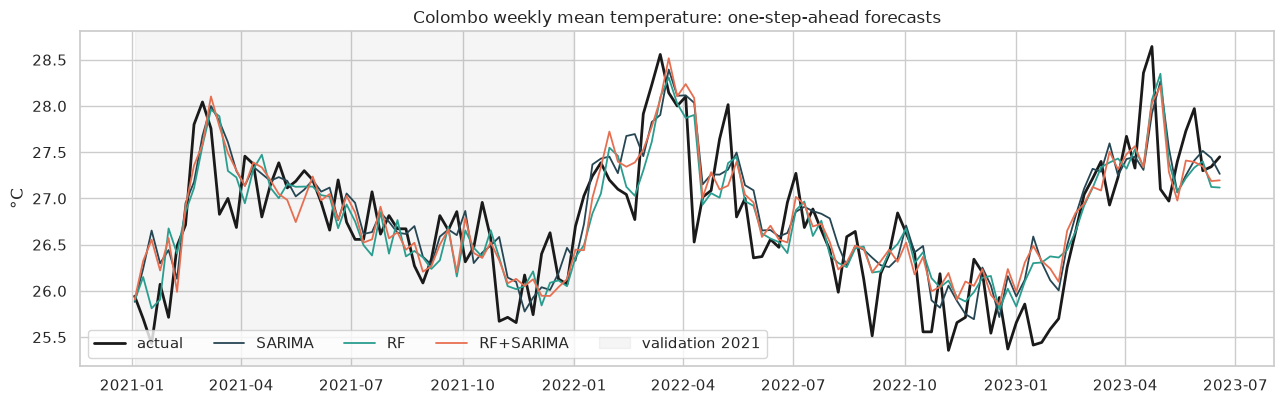

training weeks span 24.00-29.70 °C | test weeks span 25.36-28.64 °C
test weeks warmer than every training week: 0


In [27]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
w = weekly[weekly.split != "train"]
plt.figure(figsize=(13, 4.2))
plt.plot(w.index, w.actual, color="k", lw=2, label="actual")
for name, c in [("SARIMA", "#264653"), ("RF", "#2a9d8f"), ("RF+SARIMA", "#e76f51")]:
    plt.plot(w.index, w[name], color=c, lw=1.3, label=name)
plt.axvspan(w.index.min(), pd.Timestamp(fe.VAL_END), color="grey", alpha=.08, label="validation 2021")
plt.title("Colombo weekly mean temperature: one-step-ahead forecasts")
plt.ylabel("°C"); plt.legend(ncol=5); savefig("hybrid_rf_sarima")

ytr = weekly.actual[weekly.split == "train"]
yte = weekly.actual[weekly.split == "test"]
print(f"training weeks span {ytr.min():.2f}-{ytr.max():.2f} °C | test weeks span {yte.min():.2f}-{yte.max():.2f} °C")
print(f"test weeks warmer than every training week: {(yte > ytr.max()).sum()}")

**What the numbers say.** The RF on SARIMA's residuals clearly improves on SARIMA
alone, so the weather lags carry information that the pure time-series model misses.
On this test window, though, the plain RF is slightly better still, and the printout
above shows why: every test week sits inside the temperature range of the training
years.

**Why the hybrid still matters.** A random forest can only predict averages of training
targets it has already seen, because its leaves are fixed numbers. It cannot
extrapolate a trend or reach a value outside the training range. SARIMA *can*, because
its seasonal difference and drift term carry the level forward. In 2022–23 Colombo
never got hotter than the warmest training week, so the RF's blind spot was never
tested. In a warming climate it eventually will be, and then the SARIMA base is what
keeps the forecast from flattening out at the old maximum.

### 8.2 RF + ANN (next-day max temperature, all cities pooled)

* **ANN:** an `MLPRegressor` with two hidden layers (128 → 64) in a Pipeline with
  `StandardScaler` (plus one-hot city). The target is standardised too.
* **Weighted blend:** ŷ = w·RF + (1 − w)·ANN, with w picked on the 2021 validation year.
* **Residual hybrid:** the ANN learns the RF's *errors*. The errors are taken from the
  out-of-fold RF predictions in Section 7, so the ANN sees honest errors rather than
  the near-zero ones the RF makes on rows it trained on. Final = RF + λ·ANN(residual),
  where λ (how much of the correction to trust) is also picked on 2021.

residual ANN at full strength (lambda=1): test MAE 0.7549
lambda chosen on 2021: 0.15


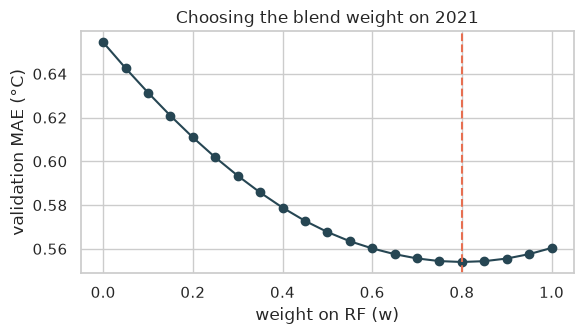

,MAE,RMSE,R2,train_time_s
RF,0.6053,0.8108,0.8478,24.37
ANN,0.7257,0.9572,0.7878,23.64
Blend (w_RF=0.8),0.5960,0.7994,0.8520,48.01
RF + ANN residual (lambda=0.15),0.5965,0.8012,0.8514,47.17


In [28]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def ann():
    return TransformedTargetRegressor(
        Pipeline([("prep", md.linear_preprocessor(FEATURES)), ("mlp", md.make_mlp())]),
        transformer=StandardScaler())

yt = Y["tmax"]
ann_m, ann_t = md.timed_fit(ann(), X[tr], yt[tr])
ann_val, ann_te = ann_m.predict(X[va]), ann_m.predict(X[te])
rf_val, rf_te = val_preds["tmax"]["RandomForest"], preds["tmax"]["RandomForest"]

weights = np.round(np.arange(0, 1.01, .05), 2)
val_mae = [md.regression_metrics(yt[va], w * rf_val + (1 - w) * ann_val)["MAE"] for w in weights]
w_best = float(weights[int(np.argmin(val_mae))])

res_target = yt[tr].values - stack_oof["tmax"]["RandomForest"].values
res_m, res_t = md.timed_fit(ann(), X[tr], res_target)
res_val, res_te = res_m.predict(X[va]), res_m.predict(X[te])
# how much of the learned correction to trust: lambda picked on 2021, like the blend weight
lam_mae = [md.regression_metrics(yt[va], rf_val + lam * res_val)["MAE"] for lam in weights]
lam_best = float(weights[int(np.argmin(lam_mae))])
resid_te = rf_te + lam_best * res_te
print(f"residual ANN at full strength (lambda=1): test MAE {md.regression_metrics(yt[te], rf_te + res_te)['MAE']:.4f}")
print(f"lambda chosen on 2021: {lam_best}")

rf_time = results["tmax"]["RandomForest"]["train_time_s"]
hyb_results["RF + ANN (next-day Tmax)"] = {
    "RF": {**md.regression_metrics(yt[te], rf_te), "train_time_s": rf_time},
    "ANN": {**md.regression_metrics(yt[te], ann_te), "train_time_s": round(ann_t, 2)},
    f"Blend (w_RF={w_best})": {**md.regression_metrics(yt[te], w_best * rf_te + (1 - w_best) * ann_te),
                               "train_time_s": round(rf_time + ann_t, 2)},
    f"RF + ANN residual (lambda={lam_best})": {**md.regression_metrics(yt[te], resid_te),
                                                "train_time_s": round(rf_time + res_t, 2)},
}
preds["tmax"]["ANN"] = ann_te
preds["tmax"]["RF+ANN blend"] = w_best * rf_te + (1 - w_best) * ann_te
preds["tmax"]["RF+ANN residual"] = resid_te

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(weights, val_mae, marker="o", color="#264653"); ax.axvline(w_best, ls="--", c="#e76f51")
ax.set(xlabel="weight on RF (w)", ylabel="validation MAE (°C)", title="Choosing the blend weight on 2021")
savefig("hybrid_blend_weight")
pd.DataFrame(hyb_results["RF + ANN (next-day Tmax)"]).T.round(4)

In [29]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
print("correlation between RF and ANN test errors:",
      round(np.corrcoef(yt[te] - rf_te, yt[te] - ann_te)[0, 1], 3))

correlation between RF and ANN test errors: 0.748


The **blend** is the winner here. On its own the ANN is clearly weaker than the RF,
but its errors are only partly correlated with the RF's, so a 20% share of ANN
cancels some of the RF's mistakes and the blend beats both of its parts. The
**residual** idea is harder than it sounds. Once a strong RF has done its job, what's
left is mostly day-to-day noise, so an ANN trained on it mainly learns noise. Used at
full strength it makes the forecast *worse*, and the λ picked on 2021 shows how
little of that correction is worth keeping.

## 9. Model comparison and interpretation

All scores below are on the **test period (2022-01-01 → 2023-06-16)**, which no model
saw during training, tuning, early stopping or blending. Rain amount is scored on the
log1p scale it was trained on.

In [30]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
for t in TASKS:
    print(f"\n=== {t} ({'higher' if MAIN[t] == 'ROC_AUC' else 'lower'} {MAIN[t]} is better) ===")
    display(table(t))


=== rain_amount (lower MAE is better) ===


,family,MAE,RMSE,R2,train_time_s
Stacking,Stacking,0.5579,0.7322,0.4755,37.10
CatBoost,Boosting,0.5585,0.7319,0.4761,3.78
XGBoost,Boosting,0.5597,0.7350,0.4715,1.57
HistGB,Boosting,0.5615,0.7398,0.4646,2.64
LightGBM,Boosting,0.5658,0.7370,0.4686,2.25
ExtraTrees,Bagging,0.5678,0.7395,0.4650,13.13
RandomForest,Bagging,0.5680,0.7367,0.4691,8.20
BaggedTrees,Bagging,0.5748,0.7494,0.4506,18.68
Linear,Baseline,0.5813,0.7521,0.4467,0.22
Persistence,Baseline,0.6043,0.8436,0.3038,0.00



=== rain_flag (higher ROC_AUC is better) ===


,family,Accuracy,F1,ROC_AUC,PR_AUC,train_time_s
Stacking,Stacking,0.8174,0.8703,0.8850,0.9453,98.11
Linear,Baseline,0.8186,0.8714,0.8825,0.9429,4.27
RandomForest,Bagging,0.8131,0.8680,0.8821,0.9435,5.08
ExtraTrees,Bagging,0.8145,0.8688,0.8802,0.9421,11.72
XGBoost,Boosting,0.8147,0.8668,0.8801,0.9419,2.72
LightGBM,Boosting,0.8127,0.8651,0.8797,0.9425,8.08
CatBoost,Boosting,0.8157,0.8676,0.8788,0.9418,9.83
HistGB,Boosting,0.8138,0.8652,0.8785,0.9415,3.17
BaggedTrees,Bagging,0.8123,0.8665,0.8694,0.9307,14.51
Climatology,Baseline,0.7493,0.8096,0.8063,0.8963,0.01



=== tmax (lower MAE is better) ===


,family,MAE,RMSE,R2,train_time_s
Stacking,Stacking,0.5892,0.7957,0.8534,98.73
HistGB,Boosting,0.5943,0.8000,0.8518,2.77
XGBoost,Boosting,0.5946,0.8006,0.8516,5.57
LightGBM,Boosting,0.5950,0.8012,0.8513,10.52
CatBoost,Boosting,0.5956,0.8007,0.8515,6.80
ExtraTrees,Bagging,0.6001,0.8050,0.8499,15.22
RandomForest,Bagging,0.6053,0.8108,0.8478,24.37
Linear,Baseline,0.6054,0.8226,0.8433,0.22
BaggedTrees,Bagging,0.6157,0.8251,0.8424,13.11
Persistence,Baseline,0.6916,0.9656,0.7841,0.00


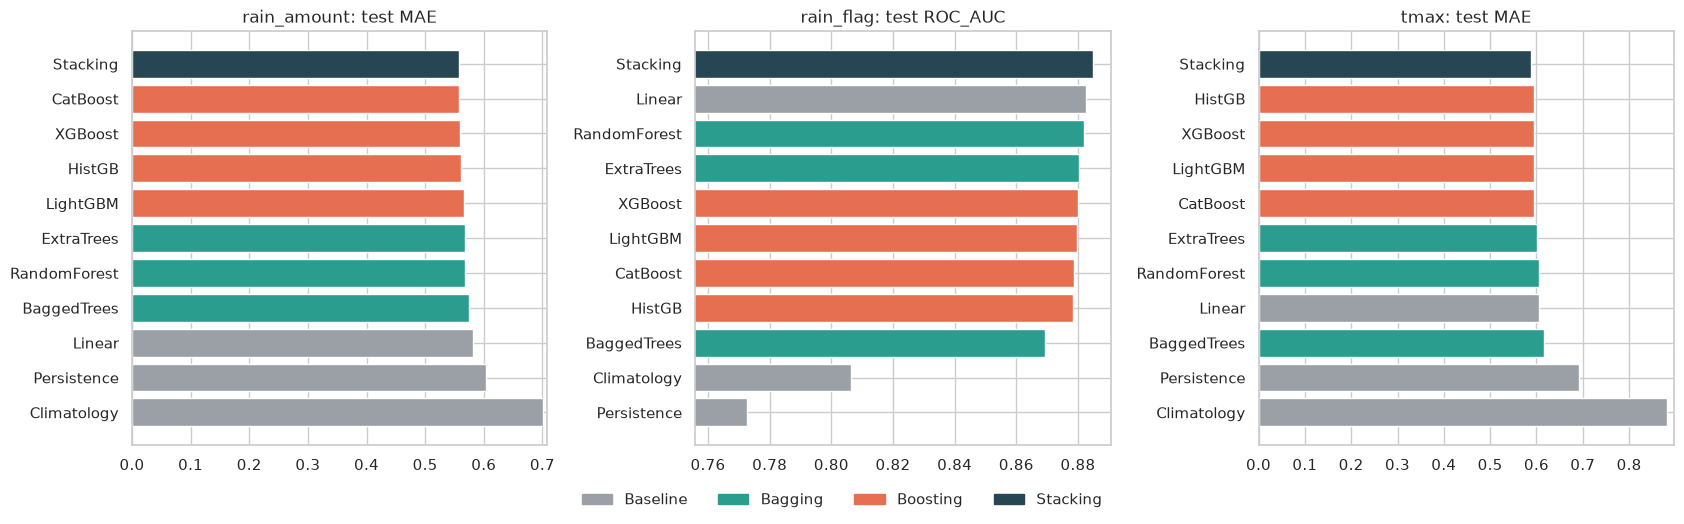

In [31]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, t in zip(ax, TASKS):
    tb = table(t)
    a.barh(tb.index[::-1], tb[MAIN[t]][::-1], color=[FAMILY_COL[f] for f in tb.family[::-1]])
    a.set_title(f"{t}: test {MAIN[t]}")
    lo, hi = tb[MAIN[t]].min(), tb[MAIN[t]].max()
    a.set_xlim(lo - (hi - lo) * .15 if MAIN[t] == "ROC_AUC" else 0, hi + (hi - lo) * .05)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=f) for f, c in FAMILY_COL.items() if f != "Hybrid"],
           loc="lower center", ncol=4, bbox_to_anchor=(.5, -.06), frameon=False)
savefig("comparison_bars")

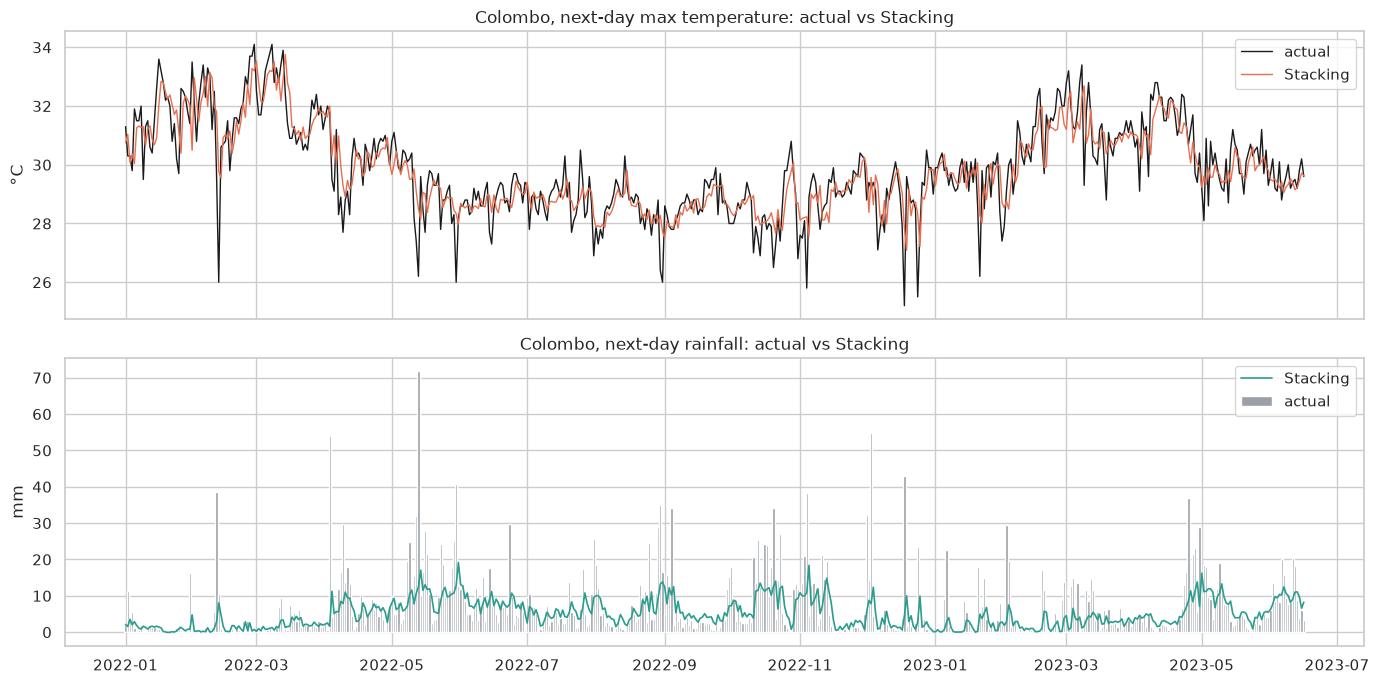

In [32]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
def best_model(t, families=("Bagging", "Boosting", "Stacking")):
    tb = table(t)
    return tb[tb.family.isin(families)].index[0]

city_mask = (CITY[te] == "Colombo").values
dates = data.time[te][city_mask]
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
bt, br = best_model("tmax"), best_model("rain_amount")
ax[0].plot(dates, Y["tmax"][te][city_mask], color="k", lw=1, label="actual")
ax[0].plot(dates, preds["tmax"][bt][city_mask], color="#e76f51", lw=1, label=bt)
ax[0].set(ylabel="°C", title=f"Colombo, next-day max temperature: actual vs {bt}"); ax[0].legend()
ax[1].bar(dates, np.expm1(Y["rain_amount"][te][city_mask]), color="#9aa0a6", width=1, label="actual")
ax[1].plot(dates, np.expm1(preds["rain_amount"][br][city_mask]), color="#2a9d8f", lw=1.2, label=br)
ax[1].set(ylabel="mm", title=f"Colombo, next-day rainfall: actual vs {br}"); ax[1].legend()
savefig("actual_vs_pred_colombo")

### Feature importance

Impurity importance comes for free with a random forest, but it is biased: it
rewards features with many possible split points and splits credit between
correlated features. Permutation importance asks the direct question instead: *how
much worse does the test score get when I shuffle this column?* SHAP then shows the
direction and size of each feature's effect for the best boosting model.

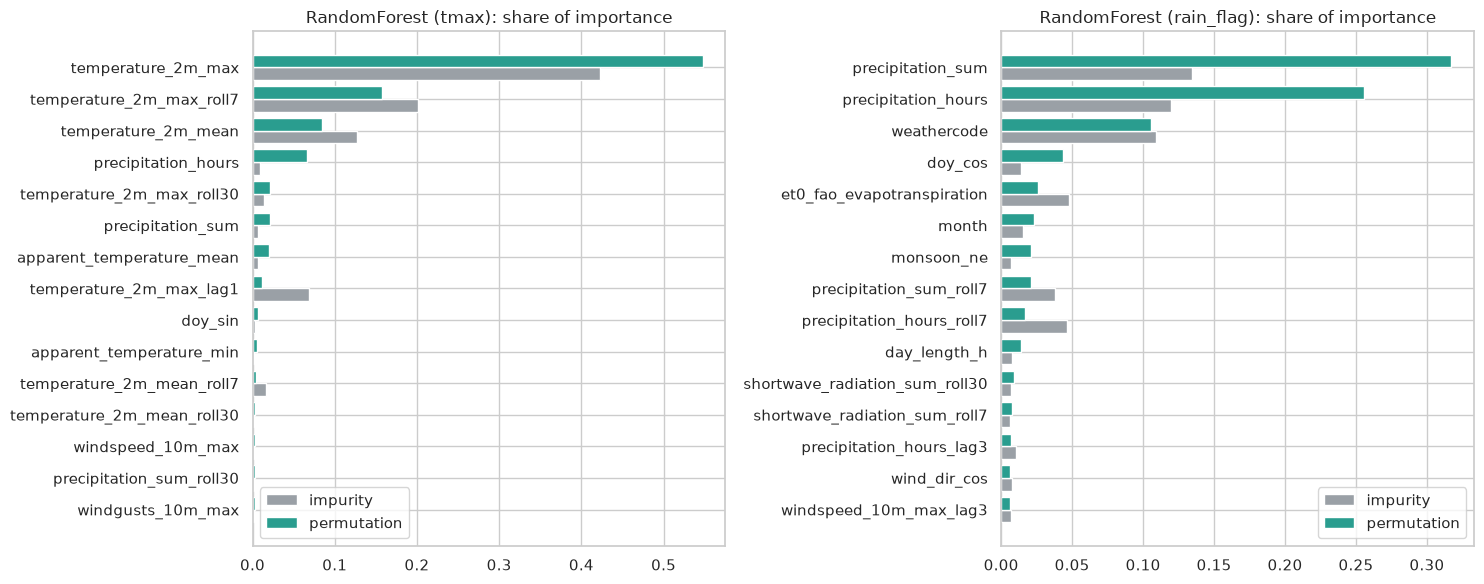

In [33]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
from sklearn.inspection import permutation_importance

imp_tables = {}
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, t in zip(ax, ["tmax", "rain_flag"]):
    rf = rf_models[t]
    samp = np.random.default_rng(0).choice(np.where(te)[0], 4000, replace=False)
    perm = permutation_importance(rf, X.iloc[samp], Y[t].iloc[samp], n_repeats=3, random_state=0,
                                  scoring="roc_auc" if md.is_clf(t) else "neg_mean_absolute_error")
    imp = pd.DataFrame({"impurity": rf.feature_importances_, "permutation": perm.importances_mean},
                       index=FEATURES)
    imp = imp / imp.abs().sum()
    imp_tables[t] = imp
    top = imp.sort_values("permutation", ascending=False).head(15)[::-1]
    yy = np.arange(len(top))
    a.barh(yy - .2, top.impurity, .4, color="#9aa0a6", label="impurity")
    a.barh(yy + .2, top.permutation, .4, color="#2a9d8f", label="permutation")
    a.set_yticks(yy, top.index); a.set_title(f"RandomForest ({t}): share of importance"); a.legend()
savefig("feature_importance_rf")

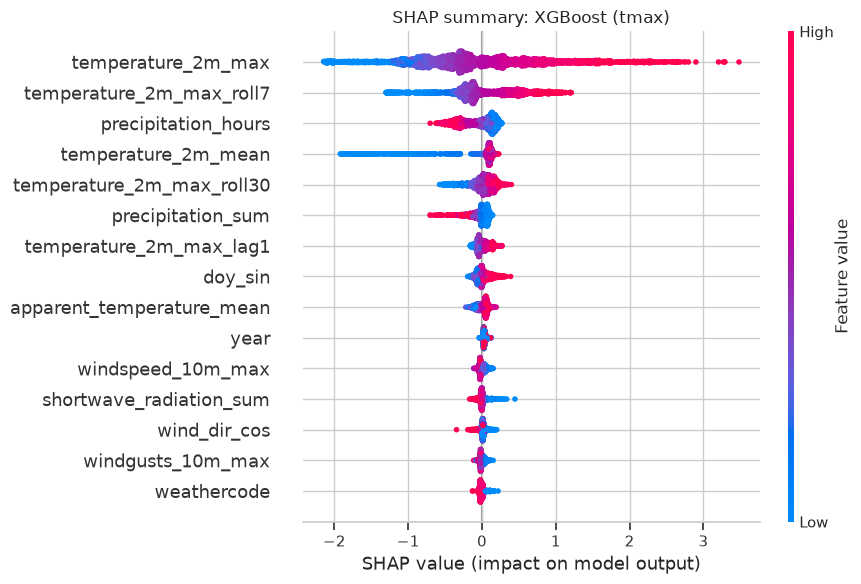

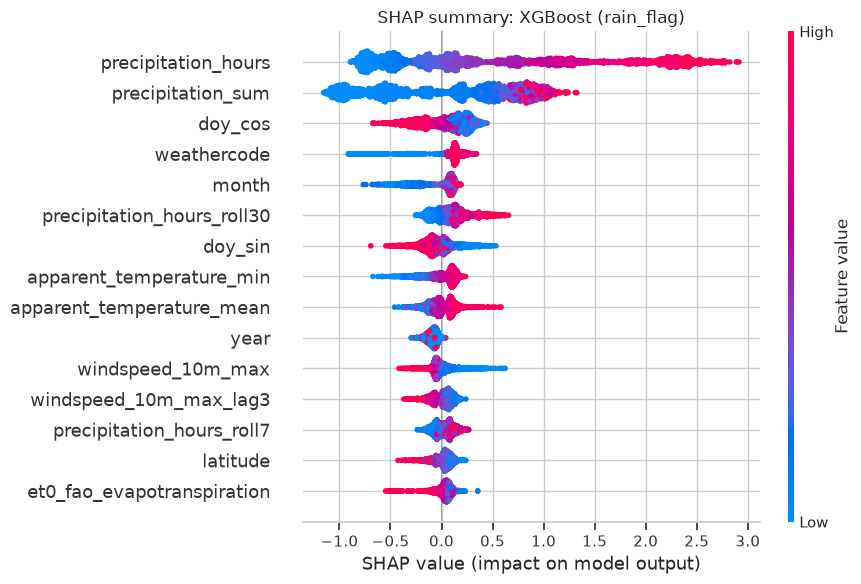

In [34]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
import shap

import xgboost as xgb
from catboost import Pool

def shap_values(name, model, rows):
    """Exact TreeSHAP values from each library's own implementation."""
    if name == "CatBoost":
        Xs = XCB.iloc[rows]
        sv = model.get_feature_importance(Pool(Xs, cat_features=["city"]), type="ShapValues")[:, :-1]
        return sv, Xs.assign(city=Xs.city.astype("category").cat.codes)
    Xs = X.iloc[rows]
    if name == "XGBoost":
        sv = model.get_booster().predict(xgb.DMatrix(Xs), pred_contribs=True)[:, :-1]
    else:  # LightGBM
        sv = model.predict(Xs, pred_contrib=True)[:, :-1]
    return sv, Xs

shap_tables = {}
SHAP_OK = ["XGBoost", "LightGBM", "CatBoost"]   # libraries with built-in TreeSHAP
for t in ["tmax", "rain_flag"]:
    tb = table(t)
    bb = [m for m in tb.index if m in SHAP_OK][0]   # best boosting model that has TreeSHAP
    model = boost_models[t][bb]
    samp = np.random.default_rng(1).choice(np.where(te)[0], 3000, replace=False)
    sv, Xshow = shap_values(bb, model, samp)
    shap_tables[t] = pd.Series(np.abs(sv).mean(0), index=Xshow.columns).sort_values(ascending=False)
    plt.figure()
    shap.summary_plot(sv, Xshow, max_display=15, show=False, plot_size=(9, 6))
    plt.title(f"SHAP summary: {bb} ({t})")
    savefig(f"shap_{t}")

### Why the models performed the way they did

* **Bagging lowers variance.** A single deep tree is very wiggly. Averaging hundreds
  on bootstrap samples (BaggedTrees) smooths that out, and the random feature subsets
  in RandomForest and ExtraTrees decorrelate the trees further, so their errors cancel
  better. Bagging can't fix bias, though: each tree is a step function, and an average
  of step functions is still a step function.
* **Boosting lowers bias, but needs early stopping.** Each round fits what is still
  wrong, so boosting picks up smooth effects such as "a little warmer every day
  through April" that bagged trees approximate coarsely. The 1,500-round curve shows
  the cost: training error keeps falling while validation error turns up. Early
  stopping on 2021 kept only a few hundred trees.
* **Stacking helps only when the base models make different mistakes.** RF, LightGBM
  and CatBoost are all tree ensembles on the same features, so their test errors are
  highly correlated (the heatmap in Section 7). The linear model is the odd one out:
  it makes *different* mistakes, so the meta-learner gives it a real share of the
  weight even though it's weaker on its own. That's why the stack edges past every
  single model on all three tasks, but only by a small margin: most of its members
  are saying the same thing.
* **Trees can't extrapolate.** A leaf predicts an average of training targets it has
  seen, so an RF never forecasts a week hotter than the hottest training week. SARIMA's
  drift and seasonal terms carry the level forward, which is why the SARIMA + RF
  hybrid is the safer design for trends. It beat SARIMA alone here, and only missed
  the plain RF because 2022–23 stayed inside the training range.
* **Rain is much harder than temperature.** Tomorrow's Tmax is mostly today's Tmax
  plus a seasonal nudge, so even persistence is strong and R² is high. Rain is
  intermittent, heavy-tailed and convective: an afternoon thunderstorm in May depends
  on local instability that daily averages at the same grid cell don't capture. The
  models learn the *season* (monsoon months and wet spells, through the rolling rain
  means) well, which shows in a good ROC-AUC for "will it rain?". The *amount* on a
  given day stays noisy, so R² for rainfall is far lower.
* **For "will it rain?", ensembles barely beat logistic regression.** Most of the
  signal is close to additive: wet season + wet last week + cloudy today. A linear
  model on good lag features captures nearly all of it, so the extra flexibility of
  trees buys very little. Good features mattered more than the choice of ensemble.

### Limits

* This is **modelled reanalysis data** (Open-Meteo, interpolated onto a grid), not
  Department of Meteorology station readings. Local extremes, especially rainfall
  totals, are smoothed out.
* **Nearby cities share grid cells**, so the 30 "cities" are fewer independent series
  than they look. Pooled scores are partly averaged over near-duplicates, and the
  random-split demo shows how badly this can inflate results.
* The test period is only 18 months, so a single unusual monsoon can shift the
  rankings.

## 10. Saving artifacts for the dashboard

The dashboard loads only these files, so it starts fast and never retrains anything.

In [35]:
# AI-assisted: generated with Claude Code, reviewed and run by the author
import joblib, os

# 1) metrics
metrics = {"tasks": results, "hybrids": hyb_results,
           "best_params_rf": {t: {k: (None if v is None else v) for k, v in p.items()} for t, p in best_params.items()},
           "best_iterations": best_iter, "rf_ann_blend_weight": w_best, "rf_ann_residual_lambda": lam_best,
           "split": {"train": f"{data.time[tr].min().date()} to {fe.TRAIN_END}", "validation": "2021",
                     "test": f"{fe.TEST_START} to {data.time[te].max().date()}"},
           "leakage_demo": demo.reset_index().to_dict(orient="records"),
           "main_metric": MAIN}
(ART / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))

# 2) test predictions (one row per city-day)
out = data.loc[te, ["time", "city", "season", "precipitation_sum", "temperature_2m_max"]].reset_index(drop=True)
out["actual_rain_mm"] = data.rain_next_mm[te].values
for t in TASKS:
    out[f"actual__{t}"] = Y[t][te].values
    for m, p in preds[t].items():
        out[f"{t}__{m}"] = p
out.to_csv(ART / "predictions_test.csv", index=False, float_format="%.5f")

# 3) hybrid outputs and feature importance
weekly.to_csv(ART / "hybrid_sarima_weekly.csv")
pd.concat({t: v for t, v in imp_tables.items()}, names=["task", "feature"]).to_csv(ART / "feature_importance_rf.csv")
pd.concat(shap_tables, names=["task", "feature"]).rename("mean_abs_shap").to_csv(ART / "shap_importance.csv")

# 4) a small daily table for the Explore / Overview pages
keep = ["time", "city", "latitude", "longitude", "elevation", "season", "precipitation_sum",
        "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean"]
daily[keep].to_parquet(ART / "daily_sample.parquet", index=False)

# 5) best ensemble model per task
for t in TASKS:
    single = {**boost_models[t], "RandomForest": rf_models[t]}
    bm = [m for m in table(t).index if m in single][0]   # best single ensemble (stacking is 4 models)
    obj = single[bm]
    path = MOD / f"{t}__{bm}.joblib"
    joblib.dump(obj, path, compress=3)
    print(f"saved {path.name}: {os.path.getsize(path) / 1e6:.1f} MB")

print(sorted(p.name for p in ART.iterdir()))
print(len(list(FIG.glob("*.png"))), "figures in artifacts/figures")

saved rain_amount__CatBoost.joblib: 0.1 MB


saved rain_flag__RandomForest.joblib: 12.5 MB
saved tmax__HistGB.joblib: 0.7 MB
['daily_sample.parquet', 'feature_importance_rf.csv', 'figures', 'hybrid_sarima_weekly.csv', 'metrics.json', 'models', 'predictions_test.csv', 'shap_importance.csv']
15 figures in artifacts/figures


## 11. AI-use declaration

As the module brief requires, here is exactly how AI was used:

* **AI-generated (Claude Code):** the code structure and code cells in this notebook,
  `src/features.py`, `src/models.py` and the Streamlit dashboard UI (`app/app.py`).
  Every AI-written cell and file starts with the comment
  `# AI-assisted: generated with Claude Code, reviewed and run by the author`.
* **Done by me:** choosing the Sri Lankan dataset and the forecasting questions,
  reviewing the missing-value and duplicate checks, interpreting the results and
  writing up the findings, and recording the video with voice-over.
* **Checking:** I ran the whole notebook top to bottom and checked every result,
  table and figure in it, as well as every number shown on the dashboard.